This notebook reproduces Fig. 7.

Experimental devices are limited by finite bandwidth, which makes impossible the implementation of the ideal pulses obtained by $(\alpha,\beta)$ hypergeometries. To simulate the finite bandwidth, we filter the pulses using a Butterworth filter, removing high-frequency contributions.

After a third-order Butterworth filter, the Fourier transform of the pulse reads
$$
\tilde{z}(\omega) = \frac{z(\omega)}{\sqrt{1 + (\omega / \omega_c)^6}},
$$
with $\omega_c=2\pi f_c$ the cut-off frequency. Here, we use the pulse with $n_+=1$ for the Landau-Zener problem (see `Fig02-LZ.ipynb`), padded with constant tails before and after the pulse. Energies are given in units of $x$, times in units of $\hbar/x$, and frequencies in units of $x/\hbar$. The cut-off frequency is $f_c=x/\hbar$, and the total pulse time in panel (a) is $t_\mathrm{f}=10\,\hbar/x$. No dephasing is included.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from parameterrun import parameterrun

from HQUAD_lib.physics_utils import fidelity_LZ, filter_pulse
from HQUAD_lib.plotting_utils import add_labels
from HQUAD_lib.QUAD_utils import solve_LZ

In [2]:
x = 1
alpha = 1
beta = 1

order = 3
fc = 1

pulse = solve_LZ(alpha, beta, x=x)

boundary_left = np.ones(len(pulse) // 5) * -10
boundary_right = np.ones(len(pulse) // 5) * 10
pulse = np.concatenate((boundary_left, pulse, boundary_right))

time = np.linspace(0, 10, len(pulse))
pulse_filtered = filter_pulse(pulse, time, order=order, fc=fc)

In [3]:
def compute_fidelity(pulse: np.ndarray, tf: float, filtered: bool = False) -> float:
    time = np.linspace(0, tf, len(pulse))

    if filtered:
        pulse = filter_pulse(pulse, time, order=order, fc=fc)

    return fidelity_LZ(-10, pulse, tf, x=x)

In [4]:
tfs = np.linspace(0.1, 100, 500)

fidelities = [
    np.asarray(
        parameterrun(compute_fidelity, "tf", tfs, pulse=pulse, filtered=filtered)
    )
    for filtered in [False, True]
]

compute_fidelity: [['tf']]:   0%|          | 0/500 [00:00<?, ?it/s]

compute_fidelity: [['tf']]:   0%|          | 0/500 [00:00<?, ?it/s]

# Plot

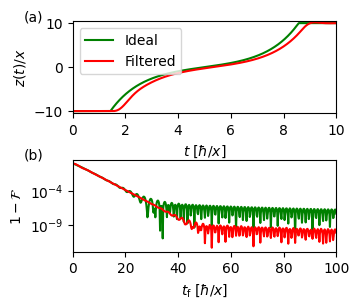

In [5]:
fig, axs = plt.subplots(2, 1, figsize=(3.4, 3))

axs[0].plot(time, pulse, c="g", label="Ideal")
axs[0].plot(time, pulse_filtered, label="Filtered", c="r")
axs[0].legend()
axs[0].set_xlabel(r"$t \; [\hbar / x]$")
axs[0].set_ylabel(r"$z(t) / x$")
axs[0].set_xlim(min(time), max(time))
axs[0].set_ylim(-10.5, 10.5)

axs[1].plot(tfs, 1 - fidelities[0], c="g")
axs[1].plot(tfs, 1 - fidelities[1], c="r")

axs[1].set_yscale("log")
axs[1].set_xlim(0, max(tfs))
axs[1].set_xlabel(r"$t_\mathrm{f}\; [\hbar / x]$")
axs[1].set_ylabel(r"$1 - \mathcal{F}$")

fig.subplots_adjust(hspace=0.5)
add_labels(axs, [-0.15, 1.05])